In [1]:
# ! pip install transformers

In [ ]:
import ssl
try:
    _create_unverified_https_context = ssl._create_unverified_context
except AttributeError:
    pass
else:
    ssl._create_default_https_context = _create_unverified_https_context

import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np 
import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud
import pickle
    
nltk.download('stopwords')

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from collections import defaultdict

# Torch ML libraries
from transformers import BertModel, BertTokenizer, AdamW, get_linear_schedule_with_warmup, RobertaModel
from torch import nn
from torch.utils.data import Dataset, DataLoader

from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')
sns.set()

# pip install boto3==1.33.13 botocore==1.33.13 awscli==1.31.13 aiobotocore==2.9.0 --ignore-installed
# pip unistall urllib3 pip install urllib3

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\91997\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [13]:
import torch
# Set intial variables and constants
%config InlineBackend.figure_format='retina'

RANDOM_SEED = 1
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [4]:
data = pd.read_csv("files/Updated_data.csv")
data.drop(columns='Unnamed: 0',inplace=True)
data.dropna(inplace=True)
data = data.head(50000)
data

,comment_text,class
0,explan edit made usernam hardcor metallica fan...,2
1,daww match background colour seem stuck thank ...,2
2,hey man realli tri edit war guy constant remov...,2
3,cannot make real suggest improv wonder section...,2
4,sir hero chanc rememb page,2
...,...,...
50022,know tri frame fake inform get unless think guess,2
50023,die though ok dont worri,2
50024,redirect talkjosã da silva canoeist,2
50025,subject sister wrote letter editor post gazett...,2


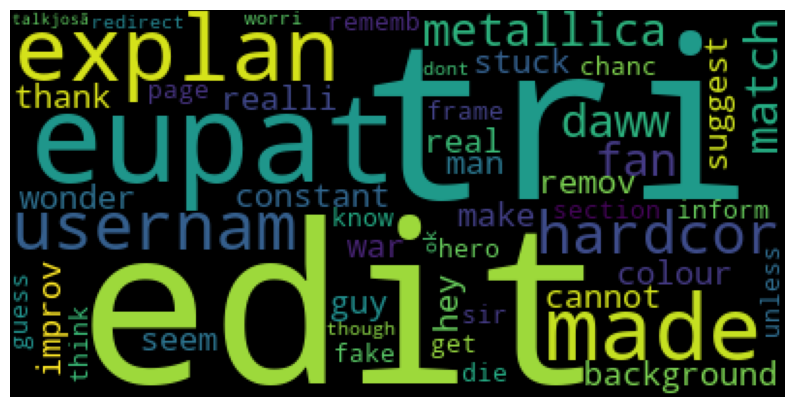

In [5]:
wordcloud = WordCloud(stopwords=stopwords.words('english'),max_words=50).generate(str(data.comment_text))
plt.figure(figsize=(10,6))
plt.imshow(wordcloud)
plt.axis('off')
plt.show()

In [6]:
x =  data.drop(columns=["class"])
y =  data['class']
x.head()

,comment_text
0,explan edit made usernam hardcor metallica fan...
1,daww match background colour seem stuck thank ...
2,hey man realli tri edit war guy constant remov...
3,cannot make real suggest improv wonder section...
4,sir hero chanc rememb page


In [7]:
# Set the model name
MODEL_NAME = 'bert-base-cased'

# Build a BERT based tokenizer
bert_tokenizer = BertTokenizer.from_pretrained(MODEL_NAME)

In [8]:
# Store length of each review 
token_lens = []

# Iterate through the content slide
for txt in data.comment_text:
    tokens = bert_tokenizer.encode(txt, truncation=True, max_length=512)
    token_lens.append(len(tokens))

Text(0.5, 0, 'Token count')

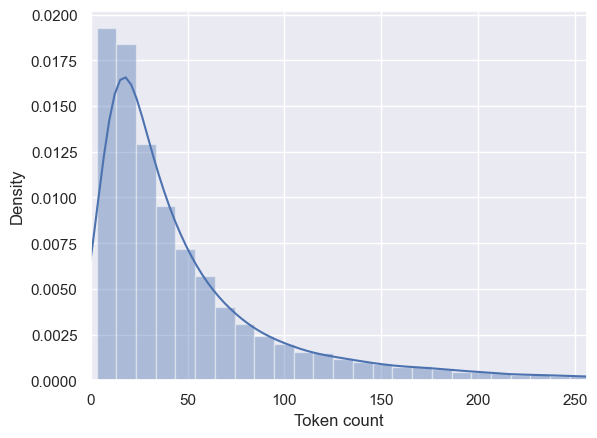

In [9]:
#Distribution Plot
sns.distplot(token_lens)
plt.xlim([0, 256])
plt.xlabel('Token count')

In [10]:
#Max Length for Sentences
MAX_LEN = 130

In [11]:
class Loading_Dataset(Dataset):
    # Constructor Function 
    def __init__(self, reviews, targets, bert_tokenizer, max_len):
        self.reviews = reviews
        self.targets = targets
        self.tokenizer = bert_tokenizer
        self.max_len = max_len
    
    def __len__(self):
        return len(self.reviews)
    
    # get item magic method
    def __getitem__(self, item):
        review = str(self.reviews[item])
        target = self.targets[item]
        
        # Encoded format to be returned 
        encoding = self.tokenizer.encode_plus( review, add_special_tokens=True, max_length=self.max_len,
            return_token_type_ids=False, pad_to_max_length=True, return_attention_mask=True, return_tensors='pt')
        
        return {
            'tweet_text': review,
            'inp_ids': encoding['input_ids'].flatten(),
            'att_mask': encoding['attention_mask'].flatten(),
            'targets': torch.tensor(target, dtype=torch.long)
        }

In [14]:
df_train, df_test = train_test_split(data, test_size=0.2, random_state=RANDOM_SEED)
df_val, df_test = train_test_split(df_test, test_size=0.5, random_state=RANDOM_SEED)

print(df_train.shape, df_val.shape, df_test.shape)

(40000, 2) (5000, 2) (5000, 2)


In [15]:
def data_loader(data, bert_tokenizer, max_len, batch_size):
    ds = Loading_Dataset( reviews=data.comment_text.to_numpy(), targets=data['class'].to_numpy(),
        bert_tokenizer=bert_tokenizer, max_len=max_len)
    
    return DataLoader(ds, batch_size=batch_size, num_workers=0)

In [16]:
# Create train, test and val data loaders
BATCH_SIZE = 16
train_loader = data_loader(df_train, bert_tokenizer, MAX_LEN, BATCH_SIZE)
val_loader = data_loader(df_val, bert_tokenizer, MAX_LEN, BATCH_SIZE)
test_loader = data_loader(df_test, bert_tokenizer, MAX_LEN, BATCH_SIZE)

In [17]:
# Examples 
data = next(iter(train_loader))

print(data.keys())
print(data['inp_ids'].shape)
print(data['att_mask'].shape)
print(data['targets'].shape)

Truncation was not explicitly activated but `max_length` is provided a specific value, please use `truncation=True` to explicitly truncate examples to max length. Defaulting to 'longest_first' truncation strategy. If you encode pairs of sequences (GLUE-style) with the tokenizer you can select this strategy more precisely by providing a specific strategy to `truncation`.


dict_keys(['tweet_text', 'inp_ids', 'att_mask', 'targets'])
torch.Size([16, 130])
torch.Size([16, 130])
torch.Size([16])


In [18]:
from transformers import RemBertModel, BertModel
# Load the BERT model
bert_model = BertModel.from_pretrained('bert-base-cased', return_dict=False)

In [19]:
class HateClassifier(nn.Module):
    
    # Constructor class 
    def __init__(self, n_classes, MODEL_NAME):
        super(HateClassifier, self).__init__()
        self.bert = BertModel.from_pretrained(MODEL_NAME, return_dict=False)
        self.rembert = RemBertModel.from_pretrained(MODEL_NAME, return_dict=False)
        self.drop = nn.Dropout(p=0.3)
        self.out = nn.Linear(self.bert.config.hidden_size + self.rembert.config.hidden_size, n_classes)
    
    # Forward propagation method
    def forward(self, inp_ids, att_mask):
        _, bert_pooled_output = self.bert(input_ids=inp_ids, attention_mask=att_mask)
        _, rembert_pooled_output = self.rembert(input_ids=inp_ids, attention_mask=att_mask)
        
        # Concatenate or combine the pooled outputs
        combined_output = torch.cat((bert_pooled_output, rembert_pooled_output), dim=1)
        
        # Add a dropout layer 
        output = self.drop(combined_output)
        
        # Pass through a linear layer for classification
        return self.out(output)


In [24]:
class_names = ['Identity Hate','Insult','No Toxicity','Obscene','Severe Toxic','Threat','Toxic']

In [25]:

model = HateClassifier(len(class_names),MODEL_NAME)
model = model.to(device)

You are using a model of type bert to instantiate a model of type rembert. This is not supported for all configurations of models and can yield errors.
Some weights of RemBertModel were not initialized from the model checkpoint at bert-base-cased and are newly initialized: ['encoder.layer.8.attention.self.key.weight', 'encoder.layer.4.attention.self.key.weight', 'encoder.layer.2.attention.self.key.bias', 'encoder.layer.10.output.dense.bias', 'encoder.layer.8.output.LayerNorm.weight', 'encoder.layer.9.output.LayerNorm.weight', 'encoder.layer.11.output.LayerNorm.weight', 'encoder.layer.0.attention.output.LayerNorm.bias', 'encoder.layer.2.attention.output.LayerNorm.weight', 'encoder.layer.1.attention.output.LayerNorm.weight', 'encoder.layer.5.output.LayerNorm.bias', 'encoder.layer.1.attention.output.dense.weight', 'encoder.layer.6.attention.output.dense.weight', 'encoder.layer.9.attention.output.dense.weight', 'encoder.layer.0.output.LayerNorm.weight', 'embeddings.LayerNorm.weight', 'enco

In [26]:
# Number of iterations 
EPOCHS = 5

# Optimizer Adam 
optimizer = AdamW(model.parameters(), lr=2e-5, correct_bias=False)

total_steps = len(train_loader) * EPOCHS

scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=0, num_training_steps=total_steps )

# Create the loss function 
loss_fn = nn.CrossEntropyLoss().to(device)

In [27]:
# Function for a single training iteration
def train_epoch(model, data_loader, loss_fn, optimizer, device, scheduler, n_examples):
    model = model.train()
    losses = []
    correct_predictions = 0
    
    for d in tqdm(data_loader):
        inp_ids = d["inp_ids"].to(device)
        att_mask = d["att_mask"].to(device)
        targets = d["targets"].to(device)
        
        outputs = model( inp_ids=inp_ids, att_mask=att_mask)
        
        _, preds = torch.max(outputs, dim=1)
        loss = loss_fn(outputs, targets)
        correct_predictions += torch.sum(preds == targets)
        losses.append(loss.item())
        
        # Backward prop
        loss.backward()
        
        # Gradient Descent
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        optimizer.zero_grad()
    
    return correct_predictions.double() / n_examples, np.mean(losses)

In [28]:
def eval_model(model, data_loader, loss_fn, device, n_examples):
    model = model.eval()
    
    losses = []
    correct_predictions = 0
    
    with torch.no_grad():
        for d in tqdm(data_loader):
            inp_ids = d["inp_ids"].to(device)
            att_mask = d["att_mask"].to(device)
            targets = d["targets"].to(device)
            
            # Get model ouptuts
            outputs = model(inp_ids=inp_ids, att_mask=att_mask)
            
            _, preds = torch.max(outputs, dim=1)
            loss = loss_fn(outputs, targets)
            
            correct_predictions += torch.sum(preds == targets)
            losses.append(loss.item())
            
    return correct_predictions.double() / n_examples, np.mean(losses)

In [30]:
history = defaultdict(list)
best_accuracy = 0

print(device)

for epoch in range(EPOCHS):
    
    # Show details 
    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print("-" * 10)
    
    train_acc, train_loss = train_epoch(model, train_loader, loss_fn, optimizer, device, scheduler, len(df_train))
    
    print(f"Train loss {train_loss} accuracy {train_acc}")

    # Get model performance (accuracy and loss)
    val_acc, val_loss = eval_model( model, val_loader, loss_fn, device,len(df_val))
    
    print(f"Val   loss {val_loss} accuracy {val_acc}")
    
    history['train_acc'].append(train_acc)
    history['train_loss'].append(train_loss)
    history['val_acc'].append(val_acc)
    history['val_loss'].append(val_loss)
    
    # If we beat prev performance
    if val_acc > best_accuracy:
        torch.save(model.state_dict(), 'bert/Rembert_Hate_detection_model.bin')
        best_accuracy = val_acc
    
  

cuda
Epoch 1/5
----------


100%|██████████| 2500/2500 [20:20<00:00,  2.05it/s]


Train loss 0.27339586596484294 accuracy 0.9139250000000001


100%|██████████| 313/313 [00:49<00:00,  6.30it/s]


Val   loss 0.2377842649089964 accuracy 0.9206000000000001
Epoch 2/5
----------


...

Val   loss 0.3046900663712135 accuracy 0.9228000000000001
Epoch 5/5
----------


100%|██████████| 2500/2500 [21:19<00:00,  1.95it/s]


Train loss 0.1198384250014089 accuracy 0.9628000000000001


100%|██████████| 313/313 [00:51<00:00,  6.07it/s]

Val   loss 0.3412221905660255 accuracy 0.9178000000000001


In [31]:
plot_history = dict()
plot_history['train_acc'] = [0,]
for i in history['train_acc']:
  plot_history['train_acc'].append(float(i))

plot_history['val_acc'] = [0,]
for i in history['val_acc']:
  plot_history['val_acc'].append(float(i))

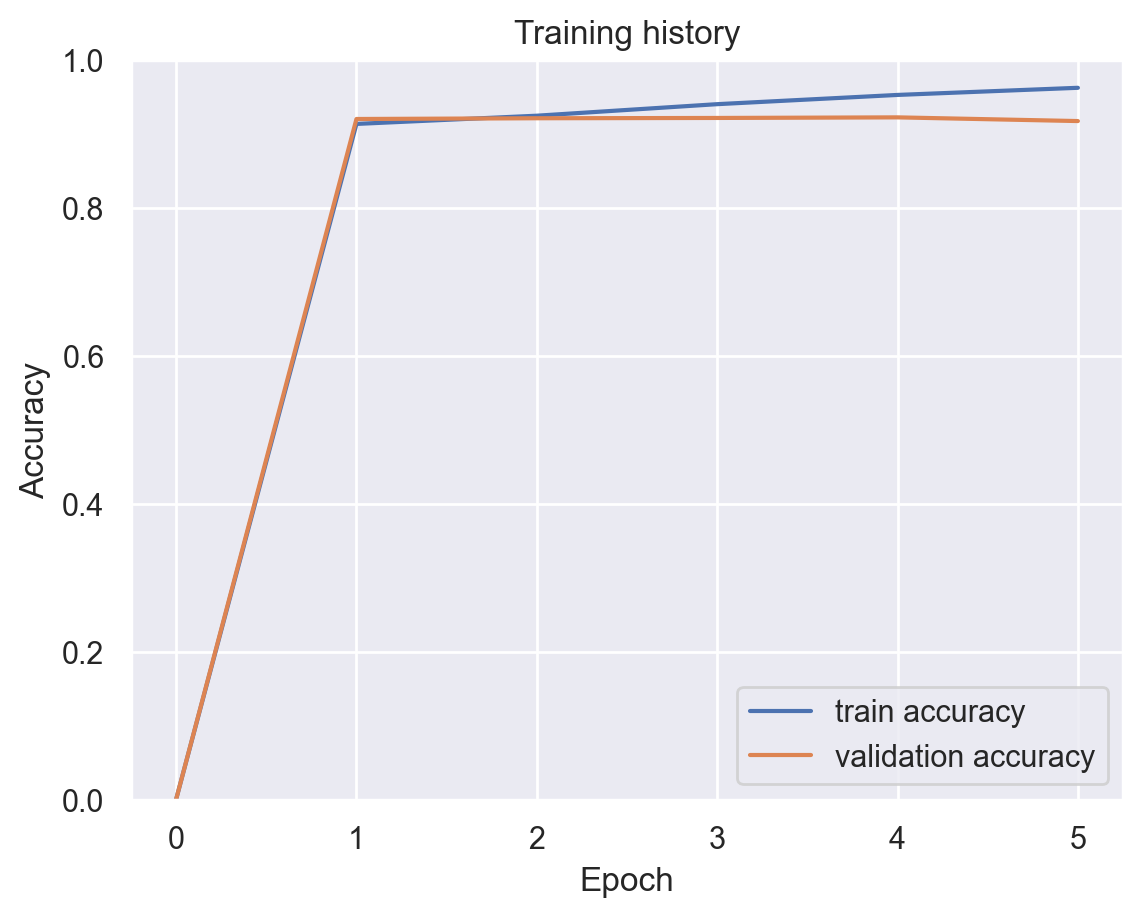

In [32]:
# Plot training and validation accuracy
plt.plot(plot_history['train_acc'], label='train accuracy')
plt.plot(plot_history['val_acc'], label='validation accuracy')

# Graph chars
plt.title('Training history')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.ylim([0, 1]);

In [33]:
train_acc, _ = eval_model(model, train_loader, loss_fn, device, len(df_train))
print()
print("Train Accuracy:",round(float(train_acc*100),2), "%")

100%|██████████| 2500/2500 [06:45<00:00,  6.16it/s]


Train Accuracy: 97.0 %


In [34]:
test_acc, _ = eval_model(model, test_loader, loss_fn, device, len(df_test))
print()
print("Test Accuracy:",round(float(test_acc*100),2), "%")

100%|██████████| 313/313 [00:49<00:00,  6.31it/s]


Test Accuracy: 91.36 %


In [35]:
tweet_text = "i wanna kill you!!!"

In [36]:
encoded_review = bert_tokenizer.encode_plus( tweet_text, max_length=MAX_LEN, add_special_tokens=True,
    return_token_type_ids=False, pad_to_max_length=True, return_attention_mask=True, return_tensors='pt')
    
inp_ids = encoded_review['input_ids'].to(device)
att_mask = encoded_review['attention_mask'].to(device)

op = model(inp_ids, att_mask)
_, pred = torch.max(op, dim=1)

print(f'Tweet text: {tweet_text}')
print(f'Predicted Sentiment  : {class_names[pred]}')

Tweet text: i wanna kill you!!!
Predicted Sentiment  : Severe Toxic


In [37]:
pickle.dump(bert_tokenizer, open("bert/rembert_bert_tokenizer.sav", 'wb'))
pickle.dump(model, open("bert/rembert_HateDetection_model.sav", 'wb'))

In [51]:
torch.save(bert_tokenizer,r"bert/rembert_bert_tokenizer.pth")
torch.save(model.state_dict(),"bert/rembert_HateDetection_model.pth")

********************************************

********************************************

********************************************

## Inference

In [2]:
import torch
import ssl
try:
    _create_unverified_https_context = ssl._create_unverified_context
except AttributeError:
    pass
else:
    ssl._create_default_https_context = _create_unverified_https_context

import seaborn as sns
import nltk
from nltk.corpus import stopwords
    
nltk.download('stopwords')

# Torch ML libraries
from transformers import BertModel, RemBertModel
from torch import nn
import warnings
warnings.filterwarnings('ignore')
sns.set()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

class HateClassifier(nn.Module):
    
    # Constructor class 
    def __init__(self, n_classes, MODEL_NAME):
        super(HateClassifier, self).__init__()
        self.bert = BertModel.from_pretrained(MODEL_NAME, return_dict=False)
        self.rembert = RemBertModel.from_pretrained(MODEL_NAME, return_dict=False)
        self.drop = nn.Dropout(p=0.3)
        self.out = nn.Linear(self.bert.config.hidden_size + self.rembert.config.hidden_size, n_classes)
    
    # Forward propagation method
    def forward(self, inp_ids, att_mask):
        _, bert_pooled_output = self.bert(input_ids=inp_ids, attention_mask=att_mask)
        _, rembert_pooled_output = self.rembert(input_ids=inp_ids, attention_mask=att_mask)
        
        # Concatenate or combine the pooled outputs
        combined_output = torch.cat((bert_pooled_output, rembert_pooled_output), dim=1)
        
        # Add a dropout layer 
        output = self.drop(combined_output)
        
        # Pass through a linear layer for classification
        return self.out(output)

def prediction_model(text):


    MAX_LEN = 130

    MODEL_NAME = 'bert-base-cased'

    class_names = ['Identity Hate','Insult','No Toxicity','Obscene','Severe Toxic','Threat','Toxic']

    #Loading Saved Models
    bert_tokenizer = torch.load(r"bert/rembert_bert_tokenizer.pth",map_location=device)
    loaded_model = HateClassifier(len(class_names), MODEL_NAME)
    loaded_model.load_state_dict(torch.load(r"bert/rembert_HateDetection_model.pth",map_location=device))
    encoded_review = bert_tokenizer.encode_plus( text, max_length=MAX_LEN, add_special_tokens=True,
        return_token_type_ids=False, pad_to_max_length=True, return_attention_mask=True, return_tensors='pt')
        
    inp_ids = encoded_review['input_ids'].to(device)
    att_mask = encoded_review['attention_mask'].to(device)

    op = loaded_model(inp_ids, att_mask)
    _, pred = torch.max(op, dim=1)

    print(f'Given text: {text}')
    print(f'Detected sentiment  : {class_names[pred]}')

    return class_names[pred]

prediction_model("everything in the world is awesome!!!")

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/rabiya/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


cpu


You are using a model of type bert to instantiate a model of type rembert. This is not supported for all configurations of models and can yield errors.
Some weights of RemBertModel were not initialized from the model checkpoint at bert-base-cased and are newly initialized: ['encoder.layer.11.attention.self.query.weight', 'encoder.layer.9.output.dense.bias', 'encoder.layer.10.attention.self.query.bias', 'encoder.layer.3.intermediate.dense.bias', 'encoder.layer.9.attention.output.LayerNorm.bias', 'encoder.layer.10.attention.self.value.weight', 'encoder.layer.5.attention.self.value.bias', 'encoder.layer.1.output.LayerNorm.bias', 'encoder.layer.9.attention.self.key.bias', 'encoder.layer.7.output.LayerNorm.bias', 'encoder.layer.7.output.dense.bias', 'encoder.layer.2.attention.self.value.bias', 'encoder.layer.0.attention.output.dense.bias', 'encoder.layer.11.intermediate.dense.weight', 'encoder.layer.4.attention.output.LayerNorm.bias', 'encoder.layer.6.output.LayerNorm.weight', 'encoder.laye

Given text: everything in the world is awesome!!!
Detected sentiment  : No Toxicity


'No Toxicity'

In [3]:
prediction_model("you are ugly!!!")

You are using a model of type bert to instantiate a model of type rembert. This is not supported for all configurations of models and can yield errors.
Some weights of RemBertModel were not initialized from the model checkpoint at bert-base-cased and are newly initialized: ['encoder.layer.11.attention.self.query.weight', 'encoder.layer.9.output.dense.bias', 'encoder.layer.10.attention.self.query.bias', 'encoder.layer.3.intermediate.dense.bias', 'encoder.layer.9.attention.output.LayerNorm.bias', 'encoder.layer.10.attention.self.value.weight', 'encoder.layer.5.attention.self.value.bias', 'encoder.layer.1.output.LayerNorm.bias', 'encoder.layer.9.attention.self.key.bias', 'encoder.layer.7.output.LayerNorm.bias', 'encoder.layer.7.output.dense.bias', 'encoder.layer.2.attention.self.value.bias', 'encoder.layer.0.attention.output.dense.bias', 'encoder.layer.11.intermediate.dense.weight', 'encoder.layer.4.attention.output.LayerNorm.bias', 'encoder.layer.6.output.LayerNorm.weight', 'encoder.laye

Given text: you are ugly!!!
Detected sentiment  : Severe Toxic


'Severe Toxic'

In [42]:
prediction_model("i hate you as a person!!!")

You are using a model of type bert to instantiate a model of type rembert. This is not supported for all configurations of models and can yield errors.
Some weights of RemBertModel were not initialized from the model checkpoint at bert-base-cased and are newly initialized: ['encoder.layer.8.attention.self.key.weight', 'encoder.layer.4.attention.self.key.weight', 'encoder.layer.2.attention.self.key.bias', 'encoder.layer.10.output.dense.bias', 'encoder.layer.8.output.LayerNorm.weight', 'encoder.layer.9.output.LayerNorm.weight', 'encoder.layer.11.output.LayerNorm.weight', 'encoder.layer.0.attention.output.LayerNorm.bias', 'encoder.layer.2.attention.output.LayerNorm.weight', 'encoder.layer.1.attention.output.LayerNorm.weight', 'encoder.layer.5.output.LayerNorm.bias', 'encoder.layer.1.attention.output.dense.weight', 'encoder.layer.6.attention.output.dense.weight', 'encoder.layer.9.attention.output.dense.weight', 'encoder.layer.0.output.LayerNorm.weight', 'embeddings.LayerNorm.weight', 'enco

Given text: i hate you as a person!!!
Detected sentiment  : Toxic


'Toxic'

In [43]:
prediction_model("i wanna kill you!!!!")

You are using a model of type bert to instantiate a model of type rembert. This is not supported for all configurations of models and can yield errors.
Some weights of RemBertModel were not initialized from the model checkpoint at bert-base-cased and are newly initialized: ['encoder.layer.8.attention.self.key.weight', 'encoder.layer.4.attention.self.key.weight', 'encoder.layer.2.attention.self.key.bias', 'encoder.layer.10.output.dense.bias', 'encoder.layer.8.output.LayerNorm.weight', 'encoder.layer.9.output.LayerNorm.weight', 'encoder.layer.11.output.LayerNorm.weight', 'encoder.layer.0.attention.output.LayerNorm.bias', 'encoder.layer.2.attention.output.LayerNorm.weight', 'encoder.layer.1.attention.output.LayerNorm.weight', 'encoder.layer.5.output.LayerNorm.bias', 'encoder.layer.1.attention.output.dense.weight', 'encoder.layer.6.attention.output.dense.weight', 'encoder.layer.9.attention.output.dense.weight', 'encoder.layer.0.output.LayerNorm.weight', 'embeddings.LayerNorm.weight', 'enco

Given text: i wanna kill you!!!!
Detected sentiment  : Severe Toxic


'Severe Toxic'

In [44]:
prediction_model("i love myself!!!!")

You are using a model of type bert to instantiate a model of type rembert. This is not supported for all configurations of models and can yield errors.
Some weights of RemBertModel were not initialized from the model checkpoint at bert-base-cased and are newly initialized: ['encoder.layer.8.attention.self.key.weight', 'encoder.layer.4.attention.self.key.weight', 'encoder.layer.2.attention.self.key.bias', 'encoder.layer.10.output.dense.bias', 'encoder.layer.8.output.LayerNorm.weight', 'encoder.layer.9.output.LayerNorm.weight', 'encoder.layer.11.output.LayerNorm.weight', 'encoder.layer.0.attention.output.LayerNorm.bias', 'encoder.layer.2.attention.output.LayerNorm.weight', 'encoder.layer.1.attention.output.LayerNorm.weight', 'encoder.layer.5.output.LayerNorm.bias', 'encoder.layer.1.attention.output.dense.weight', 'encoder.layer.6.attention.output.dense.weight', 'encoder.layer.9.attention.output.dense.weight', 'encoder.layer.0.output.LayerNorm.weight', 'embeddings.LayerNorm.weight', 'enco

Given text: i love myself!!!!
Detected sentiment  : No Toxicity


'No Toxicity'

In [45]:
prediction_model("she is a pathetic")

You are using a model of type bert to instantiate a model of type rembert. This is not supported for all configurations of models and can yield errors.
Some weights of RemBertModel were not initialized from the model checkpoint at bert-base-cased and are newly initialized: ['encoder.layer.8.attention.self.key.weight', 'encoder.layer.4.attention.self.key.weight', 'encoder.layer.2.attention.self.key.bias', 'encoder.layer.10.output.dense.bias', 'encoder.layer.8.output.LayerNorm.weight', 'encoder.layer.9.output.LayerNorm.weight', 'encoder.layer.11.output.LayerNorm.weight', 'encoder.layer.0.attention.output.LayerNorm.bias', 'encoder.layer.2.attention.output.LayerNorm.weight', 'encoder.layer.1.attention.output.LayerNorm.weight', 'encoder.layer.5.output.LayerNorm.bias', 'encoder.layer.1.attention.output.dense.weight', 'encoder.layer.6.attention.output.dense.weight', 'encoder.layer.9.attention.output.dense.weight', 'encoder.layer.0.output.LayerNorm.weight', 'embeddings.LayerNorm.weight', 'enco

Given text: she is a pathetic
Detected sentiment  : Obscene


'Obscene'